In [30]:
#import the libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.metrics import f1_score, confusion_matrix, classification_report

In [14]:
#craete the dataset
np.random.seed(10)
n = 300
data = pd.DataFrame({
    'Income': np.random.randint(20000, 150000, n),
    'Credit_Score': np.random.randint(550, 850, n),
    'Employment_Status': np.random.choice(
        ['Salaried', 'Self-Employed', 'Unemployed'], n
    ),
    'Loan_Amount': np.random.randint(50000, 1000000, n),
    'Loan_Term': np.random.choice([12, 24, 36, 48, 60], n),
    'Past_Default': np.random.choice(['Yes', 'No'], n)
})

In [15]:
#create loan status
score = (
    (data['Credit_Score'] >= 700).astype(int) * 3 +
    (data['Income'] >= 60000).astype(int) * 2 +
    (data['Employment_Status'] != 'Unemployed').astype(int) +
    (data['Loan_Amount'] <= 500000).astype(int) * 2 +
    (data['Past_Default'] == 'No').astype(int) * 3 +
    (data['Loan_Term'] <= 48).astype(int)
)

data['Loan_Status'] = (score >= 7).astype(int)
data.head()

,Income,Credit_Score,Employment_Status,Loan_Amount,Loan_Term,Past_Default,Loan_Status
0,103209,594,Unemployed,530266,60,No,0
1,125597,820,Unemployed,640910,60,No,1
2,114735,667,Self-Employed,369075,36,Yes,0
3,70496,592,Unemployed,386950,12,No,1
4,113553,751,Salaried,285283,12,No,1


In [17]:
#understanding the dataset
print("Shape of dataset:", data.shape)

print("\nColumn information:")
print(data.info())

print("\nMissing values:")
print(data.isnull().sum())

print("\nLoan status:")
print(data['Loan_Status'].value_counts())

Shape of dataset: (300, 7)

Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Income             300 non-null    int64 
 1   Credit_Score       300 non-null    int64 
 2   Employment_Status  300 non-null    object
 3   Loan_Amount        300 non-null    int64 
 4   Loan_Term          300 non-null    int64 
 5   Past_Default       300 non-null    object
 6   Loan_Status        300 non-null    int64 
dtypes: int64(5), object(2)
memory usage: 16.5+ KB
None

Missing values:
Income               0
Credit_Score         0
Employment_Status    0
Loan_Amount          0
Loan_Term            0
Past_Default         0
Loan_Status          0
dtype: int64

Loan status:
Loan_Status
1    164
0    136
Name: count, dtype: int64


In [18]:
X = data.drop('Loan_Status', axis=1)
y = data['Loan_Status']

In [19]:
le = LabelEncoder()
X['Employment_Status'] = le.fit_transform(X['Employment_Status'])
X['Past_Default'] = le.fit_transform(X['Past_Default'])
X.head()

,Income,Credit_Score,Employment_Status,Loan_Amount,Loan_Term,Past_Default
0,103209,594,2,530266,60,0
1,125597,820,2,640910,60,0
2,114735,667,1,369075,36,1
3,70496,592,2,386950,12,0
4,113553,751,0,285283,12,0


In [21]:
#splitting into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (240, 6)
Testing data: (60, 6)


In [22]:
#decision tree
dt = DecisionTreeClassifier(max_depth=5, random_state=42)
dt.fit(X_train, y_train)
dt_pred = dt.predict(X_test)

print("Decision Tree Accuracy:",
      accuracy_score(y_test, dt_pred))

Decision Tree Accuracy: 0.9166666666666666


In [23]:
#decision tree evaluation
print("Precision:",
      precision_score(y_test, dt_pred))

print("Recall:",
      recall_score(y_test, dt_pred))

print("F1 Score:",
      f1_score(y_test, dt_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, dt_pred))

Precision: 0.8387096774193549
Recall: 1.0
F1 Score: 0.9122807017543859

Confusion Matrix:
[[29  5]
 [ 0 26]]


In [24]:
print("\nClassification Report:")
print(classification_report(y_test, dt_pred))


Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.85      0.92        34
           1       0.84      1.00      0.91        26

    accuracy                           0.92        60
   macro avg       0.92      0.93      0.92        60
weighted avg       0.93      0.92      0.92        60



In [25]:
#NAIVE BAYES
nb = GaussianNB()
nb.fit(X_train, y_train)
nb_pred = nb.predict(X_test)
print("Naive Bayes Accuracy:",
      accuracy_score(y_test, nb_pred))

Naive Bayes Accuracy: 0.7666666666666667


In [26]:
#naive bayes evaluation
print("Precision:",
      precision_score(y_test, nb_pred))

print("Recall:",
      recall_score(y_test, nb_pred))

print("F1 Score:",
      f1_score(y_test, nb_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, nb_pred))

Precision: 0.6764705882352942
Recall: 0.8846153846153846
F1 Score: 0.7666666666666667

Confusion Matrix:
[[23 11]
 [ 3 23]]


In [28]:
#compare both models
results = pd.DataFrame({
    'Model': ['Decision Tree', 'Naive Bayes'],
    'Accuracy': [
        accuracy_score(y_test, dt_pred),
        accuracy_score(y_test, nb_pred)
    ],
    'Precision': [
        precision_score(y_test, dt_pred),
        precision_score(y_test, nb_pred)
    ],
    'Recall': [
        recall_score(y_test, dt_pred),
        recall_score(y_test, nb_pred)
    ],
    'F1 Score': [
        f1_score(y_test, dt_pred),
        f1_score(y_test, nb_pred)
    ]
})
results

,Model,Accuracy,Precision,Recall,F1 Score
0,Decision Tree,0.916667,0.838710,1.000000,0.912281
1,Naive Bayes,0.766667,0.676471,0.884615,0.766667


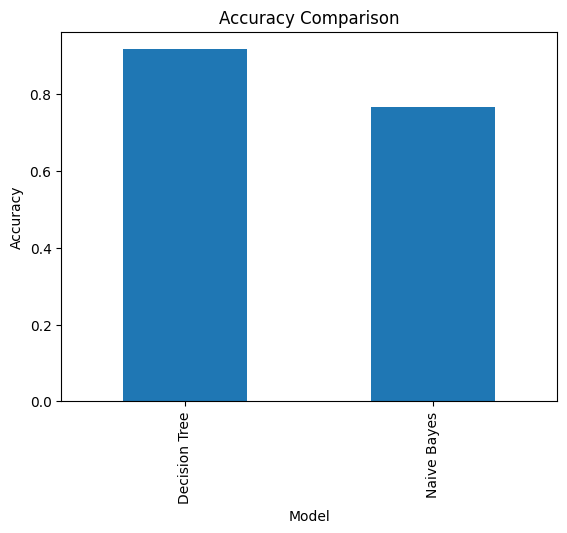

In [31]:
#accuracy graph
results.plot(
    x='Model',
    y='Accuracy',
    kind='bar',
    legend=False,
    title='Accuracy Comparison'
)

plt.ylabel('Accuracy')
plt.show()

In [33]:
print("DECISION TREE")
print("Accuracy:", accuracy_score(y_test, dt_pred))
print("Precision:", precision_score(y_test, dt_pred))
print("Recall:", recall_score(y_test, dt_pred))
print("F1 Score:", f1_score(y_test, dt_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, dt_pred))

print("\nNAIVE BAYES")
print("Accuracy:", accuracy_score(y_test, nb_pred))
print("Precision:", precision_score(y_test, nb_pred))
print("Recall:", recall_score(y_test, nb_pred))
print("F1 Score:", f1_score(y_test, nb_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, nb_pred))

DECISION TREE
Accuracy: 0.9166666666666666
Precision: 0.8387096774193549
Recall: 1.0
F1 Score: 0.9122807017543859

Confusion Matrix:
[[29  5]
 [ 0 26]]

NAIVE BAYES
Accuracy: 0.7666666666666667
Precision: 0.6764705882352942
Recall: 0.8846153846153846
F1 Score: 0.7666666666666667

Confusion Matrix:
[[23 11]
 [ 3 23]]


In [36]:
print("FINAL RESULT")

dt_acc = accuracy_score(y_test, dt_pred)
nb_acc = accuracy_score(y_test, nb_pred)

print("Decision Tree Accuracy:", round(dt_acc * 100, 2), "%")
print("Naive Bayes Accuracy:", round(nb_acc * 100, 2), "%")

print("\nModel Comparison:")
display(results)

print("\nConclusion:")
print("Both Decision Tree and Naive Bayes were successfully")
print("trained to predict loan approval.")
print("Their performance was compared using accuracy,")
print("precision, recall and F1-score.")

FINAL RESULT
Decision Tree Accuracy: 91.67 %
Naive Bayes Accuracy: 76.67 %

Model Comparison:


,Model,Accuracy,Precision,Recall,F1 Score
0,Decision Tree,0.916667,0.838710,1.000000,0.912281
1,Naive Bayes,0.766667,0.676471,0.884615,0.766667



Conclusion:
Both Decision Tree and Naive Bayes were successfully
trained to predict loan approval.
Their performance was compared using accuracy,
precision, recall and F1-score.
